# Partie 3 – Mécanisme théorique de l'alignement et dynamique par âge et par thème (ESS11)

Ce notebook prolonge les Parties 1 et 2 à partir de la base nettoyée `output/ess11_propre.csv` (29 pays européens hors Ukraine, items normalisés sur $[0, 1]$ et structurés en 10 groupes thématiques) :

1. **Configuration et chargement** de `output/ess11_propre.csv`
2. **Simulation théorique (Baldassarri & Gelman, 2008, Fig. 1)** : comment la corrélation inter-enjeux génère une polarisation agrégée sans radicalisation individuelle
3. **Analyse empirique par âge et par groupe thématique (Kozlowski & Murphy, 2021, Fig. 1)** : estimation par B-splines cubiques sur ESS11
4. **Tests de robustesse et conclusion** : indices synthétiques `idx_<groupe>` et positionnement des partis votés `parti_lr` (ParlGov)

## 0. Imports, chemins et paramètres

In [20]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.interpolate import BSpline
from scipy import stats

DOSSIER_SORTIE = Path("output")
DOSSIER_SORTIE.mkdir(exist_ok=True)

CHEMIN_PROPRE = Path("../partie1/output/ess11_propre.csv")
if not CHEMIN_PROPRE.exists():
    CHEMIN_PROPRE = Path("partie1/output/ess11_propre.csv")

if not CHEMIN_PROPRE.exists():
    raise FileNotFoundError(f"Fichier '{CHEMIN_PROPRE}' introuvable. Exécutez d'abord la Partie 1.")

PARAMS = {
    "seed": 42,
    "bg_n_samples": 25000,
    "bg_n_dist": 800,
    "bg_rhos_density": [0.0, 0.25, 0.5, 0.75, 1.0],
    "ess_min_n": 30,
    "age_bins": [14, 24, 34, 44, 54, 64, 74, 120],
    "age_labels": ["15-24", "25-34", "35-44", "45-54", "55-64", "65-74", "75+"],
    "spline_df": 3,
    "dpi": 300,
}

# Reprise exacte des 10 groupes thématiques de la Partie 1
GROUPES_ITEMS = {
    "immigration": ["immig_meme_ethnie", "immig_autre_ethnie", "immig_pays_pauvres",
                    "immig_economie", "immig_culture", "immig_pays_meilleur"],
    "lgbt_moeurs": ["lgbt_libre", "lgbt_pas_honte", "lgbt_adoption"],
    "redistribution": ["redistrib_reduire_inegalites"],
    "ecologie": ["eco_cause_humaine", "eco_responsabilite", "eco_inquietude"],
    "europe": ["europe_integration"],
    "confiance_institutionnelle": ["confiance_parlement", "confiance_justice", "confiance_police",
                                   "confiance_politiciens", "confiance_partis", "confiance_parl_europeen", "confiance_onu"],
    "satisfaction": ["satisf_economie", "satisf_gouvernement", "satisf_democratie"],
    "religiosite": ["relig_degre", "relig_assiduite", "relig_priere"],
    "genre": ["genre_emploi_egal_famille", "genre_direction_egale", "genre_salaire_egal_eco",
              "genre_parite_parlement", "genre_conge_parental_egal", "genre_licencier_insultes",
              "genre_amende_inegalite", "genre_rejet_femmes_pouvoir", "genre_rejet_femmes_offensees",
              "genre_rejet_harcelement_exagere", "genre_percoit_ecart_salaire", "genre_rejet_protection"],
    "sante": ["sante_auto_evaluee", "sante_pas_genee", "sante_pas_deprime", "sante_pas_effort",
              "sante_sommeil_calme", "sante_heureux", "sante_pas_seul", "sante_profite_vie",
              "sante_pas_triste", "sante_motive"],
}

LABELS_GROUPES = {
    "immigration": "Immigration",
    "lgbt_moeurs": "LGBT / Mœurs",
    "redistribution": "Redistribution",
    "ecologie": "Écologie",
    "europe": "Intégration européenne",
    "confiance_institutionnelle": "Confiance institutionnelle",
    "satisfaction": "Satisfaction politique",
    "religiosite": "Religiosité",
    "genre": "Égalité de genre",
    "sante": "Santé physique & mentale",
}

plt.rcParams.update({
    "font.family": "serif",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

## 1. Chargement de `ess11_propre.csv` et sous-échantillon analytique

In [21]:
def charger_base_partie3(chemin_csv):
    df_init = pd.read_csv(chemin_csv, low_memory=False)
    weight_col = next((w for w in ["anweight", "pspwght", "dweight"] if w in df_init.columns), None)
    if weight_col is None:
        df_init["unit_weight"] = 1.0
        weight_col = "unit_weight"

    df = df_init[df_init["age"].between(15, 105) & df_init["lrscale"].between(0, 10)].copy()
    df[weight_col] = pd.to_numeric(df[weight_col], errors="coerce").fillna(1.0)
    df["age_bin_p3"] = pd.cut(df["age"], bins=PARAMS["age_bins"], labels=PARAMS["age_labels"])

    print(f"Base Partie 1 : {len(df_init):,} répondants -> Sous-échantillon Partie 3 (âge & lrscale valides) : "
          f"{len(df):,} ({len(df)/len(df_init):.1%}) | Pondération : {weight_col}")
    display(df.groupby("age_bin_p3", observed=False)["age"].agg(Effectif="count", Age_Moyen="mean").round(1))
    return df, weight_col


df_ess, weight_col = charger_base_partie3(CHEMIN_PROPRE)

Base Partie 1 : 47,455 répondants -> Sous-échantillon Partie 3 (âge & lrscale valides) : 40,945 (86.3%) | Pondération : anweight


,Effectif,Age_Moyen
age_bin_p3,,
15-24,3577,20.1
25-34,4998,29.8
35-44,6340,39.6
45-54,6955,49.7
55-64,7305,59.6
65-74,6887,69.3
75+,4883,80.4


## 2. Modèle théorique : polarisation par corrélation sans radicalisation (Baldassarri & Gelman, 2008)

On simule $K = 4$ dimensions d'opinion suivant $\mathbf{X}_i \sim \mathcal{N}_4(\mathbf{0}, \boldsymbol{\Sigma}_\rho)$ avec corrélation paire-à-paire uniforme $\rho \in [0, 1]$ :
* **Aucune radicalisation marginale :** chaque dimension conserve une distribution $\mathcal{N}(0, 1)$ quel que soit $\rho$.
* **Dispersion agrégée :** la variance du score moyen $\bar{X}_i = \frac{1}{4}\sum_{k=1}^4 X_{ik}$ vaut $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ et quadruple lorsque $\rho$ passe de $0$ à $1$, abaissant la densité au centre modéré au profit des extrémités(Panneau A) tout en rapprochant les individus d'un même camp et en éloignant les camps opposés en distance de Manhattan (Panneau B).

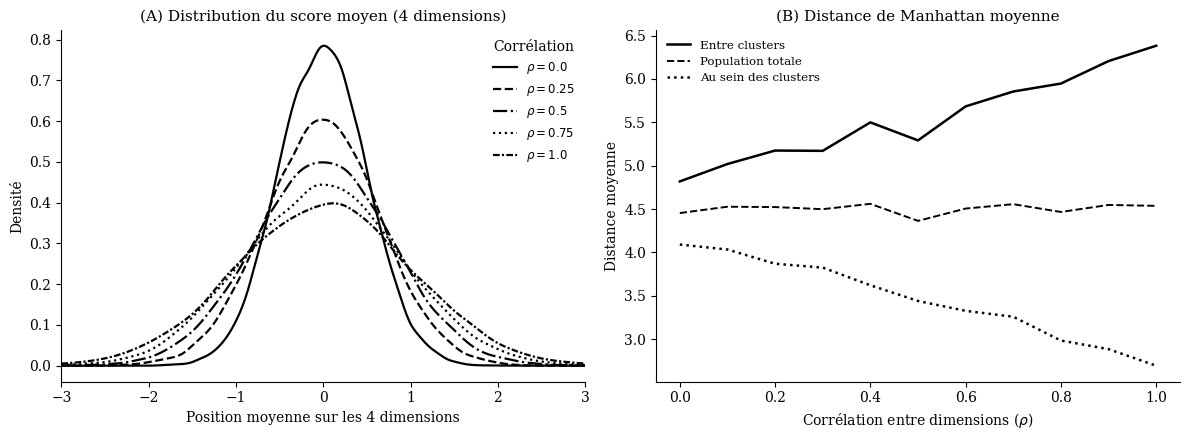

In [22]:
def generate_bg_figure1(output_pdf):
    rng = np.random.default_rng(PARAMS["seed"])
    linestyles = ["-", "--", "-.", ":", (0, (3, 1, 1, 1))]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    # Panneau A : Densité du score idéologique moyen
    grid_x = np.linspace(-3, 3, 400)
    for rho, ls in zip(PARAMS["bg_rhos_density"], linestyles):
        cov = np.full((4, 4), rho)
        np.fill_diagonal(cov, 1.0)
        mean_score = rng.multivariate_normal(np.zeros(4), cov, size=PARAMS["bg_n_samples"]).mean(axis=1)
        bw = max(1.06 * np.std(mean_score, ddof=1) * (len(mean_score) ** (-0.2)), 0.03)
        kde = np.exp(-0.5 * ((grid_x[:, None] - mean_score[None, :]) / bw) ** 2).mean(axis=1) / (bw * np.sqrt(2 * np.pi))
        axes[0].plot(grid_x, kde, linestyle=ls, color="black", linewidth=1.6, label=rf"$\rho = {rho}$")

    axes[0].set_title("(A) Distribution du score moyen (4 dimensions)")
    axes[0].set_xlabel("Position moyenne sur les 4 dimensions")
    axes[0].set_ylabel("Densité")
    axes[0].set_xlim(-3, 3)
    axes[0].legend(title="Corrélation", frameon=False)

    # Panneau B : Distance de Manhattan moyenne
    rho_grid = np.linspace(0.0, 1.0, 11)
    all_d, bet_d, wit_d = [], [], []
    for rho in rho_grid:
        cov = np.full((4, 4), rho)
        np.fill_diagonal(cov, 1.0)
        X = rng.multivariate_normal(np.zeros(4), cov, size=PARAMS["bg_n_dist"])
        clusters = (X.mean(axis=1) >= 0).astype(int)
        dmat = squareform(pdist(X, metric="cityblock"))
        iu = np.triu_indices(len(X), k=1)
        vals, same = dmat[iu], (clusters[iu[0]] == clusters[iu[1]])
        all_d.append(vals.mean())
        bet_d.append(vals[~same].mean())
        wit_d.append(vals[same].mean())

    axes[1].plot(rho_grid, bet_d, "-", color="black", lw=1.8, label="Entre clusters")
    axes[1].plot(rho_grid, all_d, "--", color="black", lw=1.4, label="Population totale")
    axes[1].plot(rho_grid, wit_d, ":", color="black", lw=1.8, label="Au sein des clusters")
    axes[1].set_title("(B) Distance de Manhattan moyenne")
    axes[1].set_xlabel(r"Corrélation entre dimensions ($\rho$)")
    axes[1].set_ylabel("Distance moyenne")
    axes[1].legend(frameon=False)

    plt.tight_layout()
    plt.savefig(output_pdf, dpi=PARAMS["dpi"], bbox_inches="tight")
    plt.show()


generate_bg_figure1(DOSSIER_SORTIE / "fig1_bg_simulation.pdf")

### Interprétation de la simulation (Baldassarri & Gelman, 2008)

Cette simulation illustre comment l'alignement entre différentes opinions peut accroître les écarts entre citoyens sans que leurs positions sur chaque sujet pris isolément ne deviennent plus extrêmes. Par construction, chacune des quatre dimensions d'opinion suit toujours la même loi normale centrée sur $0$ : les individus ne se radicalisent pas sur chaque question prise séparément.

En revanche, lorsque la corrélation $\rho$ entre les questions augmente :
* **Panneau (A) – Aplatissement de la distribution :** La distribution du score moyen $\bar{X}_i$ reste **en cloche (unimodale) et centrée sur $0$**, mais sa variance $\mathrm{Var}(\bar{X}_i) = \frac{1 + 3\rho}{4}$ est multipliée par quatre entre $\rho = 0$ et $\rho = 1$. Conformément aux conclusions de Baldassarri et Gelman (2008), la hausse de $\rho$ ne crée pas deux camps séparés, mais **aplatit et étire la distribution**, augmentant la proportion d'individus ayant des profils cohérents à gauche ou à droite.
* **Panneau (B) – Écartement entre camps :** La distance moyenne entre les individus situés à gauche ($\bar{X}_i < 0$) et ceux situés à droite ($\bar{X}_i \ge 0$) augmente nettement avec $\rho$, tandis que les individus d'un même camp deviennent plus proches les uns des autres.

## 3. Alignement idéologique par groupe thématique selon l'âge (Kozlowski & Murphy, 2021)

Pour chaque tranche d'âge décennale $a$ et chaque item $X_j$ du groupe thématique $g(j)$, on mesure l'intensité de la contrainte idéologique par la corrélation pondérée en valeur absolue $|r_{j,a}| = |\mathrm{Corr}_{w}(X_j, \mathrm{lrscale} \mid \mathrm{age} \in a)|$, puis on lisse les trajectoires de chacun des **10 groupes de la Partie 1** par B-splines cubiques ($\mathrm{df} = 3$) avec intervalles de confiance à $95\%$.

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.257,0.063,0.261,0.384
LGBT / Mœurs,0.203,0.045,0.196,0.281
Redistribution,0.202,0.032,0.208,0.256
Intégration européenne,0.194,0.043,0.179,0.270
Écologie,0.181,0.067,0.181,0.311
Religiosité,0.169,0.040,0.172,0.246
Égalité de genre,0.109,0.052,0.107,0.230
Satisfaction politique,0.106,0.042,0.115,0.179
Confiance institutionnelle,0.054,0.043,0.041,0.190


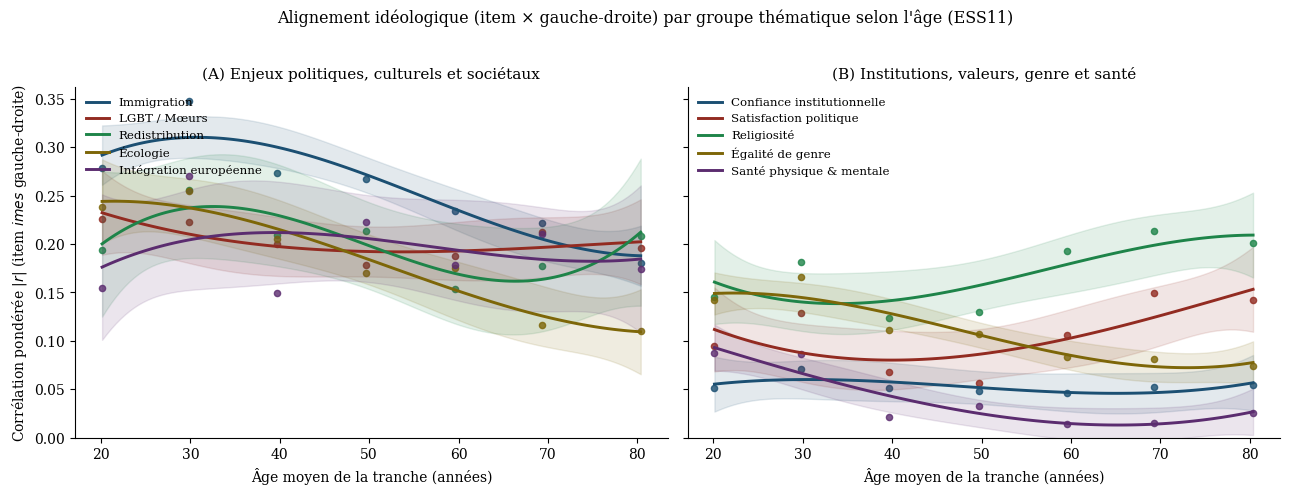

In [23]:
def weighted_corr(x, y, w):
    mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if mask.sum() < PARAMS["ess_min_n"]:
        return np.nan
    x, y, w = x[mask], y[mask], w[mask]
    w_norm = w / np.sum(w)
    dx, dy = x - np.sum(w_norm * x), y - np.sum(w_norm * y)
    denom = np.sqrt(np.sum(w_norm * dx**2) * np.sum(w_norm * dy**2))
    return np.sum(w_norm * dx * dy) / denom if denom > 0 else np.nan


def fit_predict_bspline_by_group(corr_df, age_grid, df_spline=3, alpha=0.05):
    groups = sorted(corr_df["groupe"].unique())
    x_all, y_all = corr_df["age_mid"].to_numpy(), corr_df["abs_corr"].to_numpy()
    degree = 3
    n_int = max(0, df_spline - degree)
    int_knots = np.quantile(x_all, np.linspace(0, 1, n_int + 2)[1:-1]) if n_int > 0 else np.array([])
    knots = np.concatenate(([x_all.min()] * (degree + 1), int_knots, [x_all.max()] * (degree + 1)))

    B_obs = BSpline.design_matrix(x_all, knots, degree).toarray()[:, 1:]
    B_grid = BSpline.design_matrix(age_grid, knots, degree).toarray()[:, 1:]

    X_design = np.hstack([
        np.hstack([ind := (corr_df["groupe"].to_numpy() == g).astype(float)[:, None], ind * B_obs])
        for g in groups
    ])
    beta, _, _, _ = np.linalg.lstsq(X_design, y_all, rcond=None)
    resid = y_all - X_design @ beta
    dof = max(len(y_all) - np.linalg.matrix_rank(X_design), 1)
    cov_beta = (np.sum(resid**2) / dof) * np.linalg.pinv(X_design.T @ X_design)
    t_crit = stats.t.ppf(1.0 - alpha / 2.0, df=dof)

    preds = {}
    for idx_g, g in enumerate(groups):
        X_grid = np.hstack([
            np.hstack([np.ones((len(age_grid), 1)), B_grid]) if j == idx_g
            else np.zeros((len(age_grid), 1 + B_grid.shape[1]))
            for j in range(len(groups))
        ])
        mean_pred = X_grid @ beta
        se_pred = np.sqrt(np.maximum(np.sum((X_grid @ cov_beta) * X_grid, axis=1), 0.0))
        preds[g] = {"mean": mean_pred, "ci_lower": mean_pred - t_crit * se_pred, "ci_upper": mean_pred + t_crit * se_pred}
    return preds


def analyser_alignement_age_thematiques(df, groupes_dict, weight_col, target_col="lrscale", titre="", ylabel="", output_pdf=None):
    records = [
        {"age_mid": grp["age"].mean(), "groupe": g, "label": LABELS_GROUPES.get(g, g),
         "abs_corr": abs(r)}
        for _, grp in df.groupby("age_bin_p3", observed=False)
        for g, cols in groupes_dict.items()
        for col in cols if col in grp.columns
        if np.isfinite(r := weighted_corr(
            pd.to_numeric(grp[col], errors="coerce").to_numpy(),
            pd.to_numeric(grp[target_col], errors="coerce").to_numpy(),
            grp[weight_col].to_numpy()
        ))
    ]
    corr_df = pd.DataFrame(records)
    summary = (corr_df.groupby("label")["abs_corr"]
               .agg(Moyenne="mean", Ecart_Type="std", Mediane="median", Max="max")
               .sort_values("Moyenne", ascending=False))
    display(summary.round(3))

    age_grid = np.linspace(corr_df["age_mid"].min(), corr_df["age_mid"].max(), 120)
    preds = fit_predict_bspline_by_group(corr_df, age_grid, df_spline=PARAMS["spline_df"])

    panneaux = [
        (["immigration", "lgbt_moeurs", "redistribution", "ecologie", "europe"], "(A) Enjeux politiques, culturels et sociétaux"),
        (["confiance_institutionnelle", "satisfaction", "religiosite", "genre", "sante"], "(B) Institutions, valeurs, genre et santé"),
    ]
    palette = ["#1b4f72", "#922b21", "#1e8449", "#7d6608", "#5b2c6f"]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)

    for ax, (liste_g, sous_titre) in zip(axes, panneaux):
        for idx, g in enumerate(liste_g):
            if g not in preds:
                continue
            c, res = palette[idx % len(palette)], preds[g]
            ax.plot(age_grid, res["mean"], color=c, lw=2.1, label=LABELS_GROUPES.get(g, g))
            ax.fill_between(age_grid, res["ci_lower"], res["ci_upper"], color=c, alpha=0.12)
            pts = corr_df[corr_df["groupe"] == g].groupby("age_mid")["abs_corr"].mean().reset_index()
            ax.scatter(pts["age_mid"], pts["abs_corr"], color=c, s=20, alpha=0.8)
        ax.set_title(sous_titre)
        ax.set_xlabel("Âge moyen de la tranche (années)")
        ax.set_ylim(bottom=0)
        ax.legend(frameon=False, loc="upper left")

    axes[0].set_ylabel(ylabel)
    fig.suptitle(titre, fontsize=11.5, y=1.02)
    plt.tight_layout()
    if output_pdf:
        plt.savefig(output_pdf, dpi=PARAMS["dpi"], bbox_inches="tight")
    plt.show()
    return corr_df, summary


corr_main, summary_main = analyser_alignement_age_thematiques(
    df_ess, GROUPES_ITEMS, weight_col, target_col="lrscale",
    titre="Alignement idéologique (item × gauche-droite) par groupe thématique selon l'âge (ESS11)",
    ylabel=r"Corrélation pondérée $|r|$ (item $	imes$ gauche-droite)",
    output_pdf=DOSSIER_SORTIE / "fig2_kozlowski_ess11_age.pdf"
)

#### Interprétation de l'alignement idéologique par groupe thématique selon l'âge (Figure 2)

Cette figure présente une **adaptation transversale** de la méthode de Kozlowski et Murphy (2021) appliquée aux sept tranches d'âge de l'enquête ESS11 ($N = 40\,945$). Les courbes correspondent à un lissage cubique ($\mathrm{df} = 3$, équivalent à un polynôme de degré 3 ajusté sur les sept tranches d'âge) des corrélations pondérées en valeur absolue $|r_{j,a}|$ entre chaque question et l'auto-positionnement gauche-droite (`lrscale`), accompagnées de leurs intervalles de confiance à 95 %.

Quatre enseignements principaux se dégagent :

1. **Une hiérarchie nette entre enjeux politiques (Panneau A) et thèmes sociaux ou témoins (Panneau B) :**
   * **L'immigration** arrive nettement en tête ($|r| = 0,257$) et constitue le sujet le plus structuré par le clivage gauche-droite entre 20 et 70 ans.
   * Un bloc serré suit immédiatement derrière dans le **Panneau (A)**, réunissant les **questions LGBT / mœurs** ($0,203$), la **redistribution économique** ($0,202$) et **l'intégration européenne** ($0,194$), l'ensemble des courbes de ce panneau évoluant entre $|r| \approx 0,11$ et $0,35$.
   * **L'écologie** ($0,181$) et **la religiosité** ($0,169$) occupent une position intermédiaire, suivies par **l'égalité de genre** ($0,109$) et **la satisfaction politique** ($0,106$).
   * Conformément aux attentes, les **thèmes témoins** que sont la **confiance institutionnelle** ($0,054$) et la **santé physique et mentale** ($0,041$) présentent des corrélations quasi nulles sur l'ensemble du spectre d'âge, confirmant qu'ils ne relèvent pas d'un alignement gauche-droite.

2. **Complémentarité des clivages économiques et culturels :**

   L'organisation des opinions autour de l'axe gauche-droite en Europe ne repose pas uniquement sur les questions économiques (redistribution), mais s'appuie tout autant sur les enjeux migratoires, sociétaux et européens. Aux âges élevés (vers 80 ans), quatre des cinq dimensions du Panneau (A) — immigration, LGBT / mœurs, redistribution et intégration européenne — convergent d'ailleurs dans une fourchette resserrée autour de $|r| \approx 0,18\text{–}0,21$.

3. **Des dynamiques différenciées selon l'âge (absence d'un sous-alignement généralisé des plus jeunes) :**
   * **Décroissance avec l'âge :** Contrairement à l'idée d'un alignement uniformément plus faible chez les `15-24` ans, plusieurs clivages structurants sont plus marqués chez les jeunes adultes que chez les seniors. L'**immigration** culmine autour de $0,31$ vers 30 ans (avec un point observé à $0,35$) avant de décroître régulièrement jusqu'à $\approx 0,19$ vers 80 ans. De même, l'**écologie** (passant de $\approx 0,25$ à 20–30 ans à $\approx 0,11$ à 80 ans), l'**égalité de genre** (de $\approx 0,15$ à $\approx 0,07\text{–}0,08$) et la **santé** (de $\approx 0,09$ à $\approx 0,01\text{–}0,02$) diminuent au fil des tranches d'âge.
   * **Stabilité relative :** Les enjeux **LGBT / mœurs** (courbe comprise entre $0,19$ et $0,23$), la **redistribution** ($0,16\text{–}0,24$), l'**intégration européenne** ($0,18\text{–}0,21$, malgré une dispersion notable des points observés entre $0,15$ et $0,27$) et la **confiance institutionnelle** ($\approx 0,05\text{–}0,06$) ne présentent pas de tendance monotone sur l'ensemble du spectre.
   * **Profils croissants ou en U :** Seule la **religiosité** progresse nettement avec l'âge après 35 ans (passant d'un minimum lissé de $\approx 0,14$ à $\approx 0,21$ vers 80 ans), tandis que la **satisfaction politique** décrit une courbe en U avec un creux autour de $0,08$ vers 40–45 ans contre $\approx 0,11$ à 20 ans et $\approx 0,15$ à 80 ans.

4. **Précautions d'interprétation (coupe transversale et incertitude statistique) :**

   L'élargissement des bandes de confiance à 95 % aux extrémités d'âge (20 et 80 ans) ainsi que sur les thèmes à forte dispersion (intégration européenne, redistribution) invite à ne pas surinterpréter les inflexions locales des splines. Enfin, l'enquête ESS11 étant réalisée sur une seule vague, ces courbes mesurent uniquement des écarts transversaux entre générations présentes au moment de l'enquête, sans permettre d'isoler un effet propre au vieillissement.

## 4. Analyses de sensibilité et conclusion

Afin de vérifier que les trajectoires observées en Section 3 ne résultent pas d'artefacts de mesure propres aux questions isolées ou à l'auto-positionnement déclaré (`lrscale`), nous reconduisons l'estimation par B-splines à l'aide de deux variables construites en **Partie 1** :

1. **Indices thématiques synthétiques (`idx_<groupe>`) — validation interne (`fig3`) :**
   * *Principe :* chaque indice agrège par moyenne les items normalisés d'un même domaine (par exemple les 6 questions sur l'immigration dans `idx_immigration` ou les 12 items sur l'égalité de genre dans `idx_genre`).
   * *Intérêt méthodologique :* cette agrégation neutralise le bruit aléatoire propre aux items isolés (*biais d'atténuation* qui tire les corrélations vers zéro) et accorde un poids strictement égal à chacun des 10 thèmes, indépendamment de son nombre initial de questions.
2. **Positionnement gauche-droite du parti voté (`parti_lr`, ParlGov) — validation externe (`fig4`) :**
   * *Principe :* sur le sous-échantillon des électeurs dont le vote déclaré est rattaché à la base ParlGov ($N \ge 500$), on remplace l'auto-placement subjectif `lrscale` par le score gauche-droite objectif attribué par des experts au parti choisi lors des dernières élections législatives.
   * *Intérêt méthodologique :* ce test écarte les biais de subjectivité ou de rationalisation liés à l'auto-étiquetage politique et vérifie que l'alignement des attitudes par âge se traduit concrètement dans le **comportement électoral** effectif.

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.319,0.064,0.322,0.428
LGBT / Mœurs,0.243,0.018,0.240,0.264
Écologie,0.232,0.070,0.222,0.316
Égalité de genre,0.228,0.058,0.225,0.326
Redistribution,0.202,0.032,0.208,0.256
Intégration européenne,0.194,0.043,0.179,0.270
Religiosité,0.189,0.041,0.202,0.235
Satisfaction politique,0.124,0.043,0.120,0.175
Santé physique & mentale,0.058,0.057,0.029,0.140


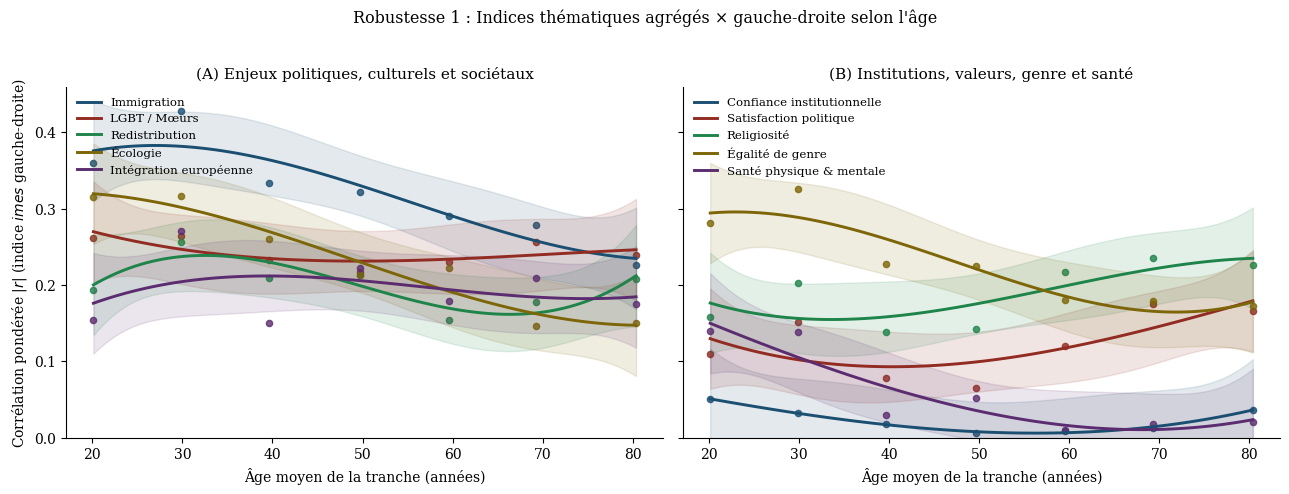

,Moyenne,Ecart_Type,Mediane,Max
label,,,,
Immigration,0.297,0.046,0.304,0.390
Intégration européenne,0.266,0.026,0.260,0.303
Écologie,0.217,0.058,0.213,0.357
Redistribution,0.205,0.038,0.212,0.272
LGBT / Mœurs,0.198,0.068,0.179,0.318
Religiosité,0.138,0.039,0.142,0.204
Confiance institutionnelle,0.125,0.062,0.107,0.274
Égalité de genre,0.097,0.052,0.094,0.210
Satisfaction politique,0.060,0.039,0.053,0.146


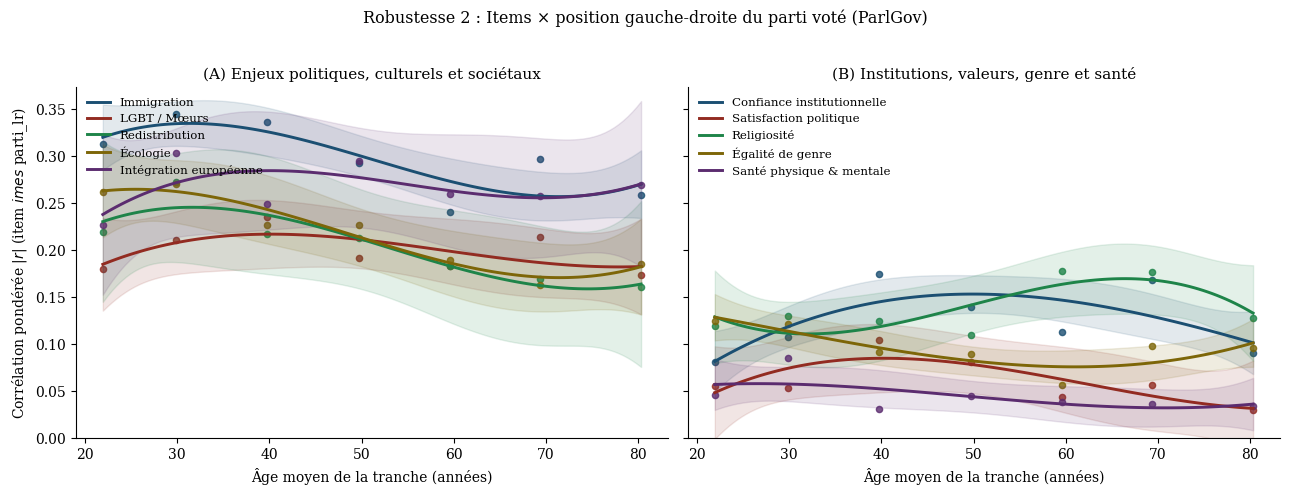

In [24]:
# Robustesse 1 : Indices thématiques agrégés (idx_<groupe>)
GROUPES_INDICES = {g: [f"idx_{g}"] for g in GROUPES_ITEMS if f"idx_{g}" in df_ess.columns}
analyser_alignement_age_thematiques(
    df_ess, GROUPES_INDICES, weight_col, target_col="lrscale",
    titre="Robustesse 1 : Indices thématiques agrégés × gauche-droite selon l'âge",
    ylabel=r"Corrélation pondérée $|r|$ (indice $	imes$ gauche-droite)",
    output_pdf=DOSSIER_SORTIE / "fig3_robustesse_indices_thematiques.pdf"
)

# Robustesse 2 : Positionnement gauche-droite du parti voté (ParlGov)
if "parti_lr" in df_ess.columns and df_ess["parti_lr"].notna().sum() >= 500:
    analyser_alignement_age_thematiques(
        df_ess[df_ess["parti_lr"].notna()], GROUPES_ITEMS, weight_col, target_col="parti_lr",
        titre="Robustesse 2 : Items × position gauche-droite du parti voté (ParlGov)",
        ylabel=r"Corrélation pondérée $|r|$ (item $	imes$ parti_lr)",
        output_pdf=DOSSIER_SORTIE / "fig4_robustesse_parti_parlgov.pdf"
    )

#### Interprétation du test par indices thématiques (`idx_<groupe>`)

Le remplacement des 49 questions individuelles par des scores moyens agrégés par thème élève mécaniquement le niveau global des corrélations en réduisant la variance propre à chaque question isolée. 

Sur le fond, les conclusions de la Section 3 sont confirmées :
* La hiérarchie entre enjeux reste stable, avec une nette domination de l'immigration, des questions culturelles et de la redistribution face aux thèmes témoins (confiance institutionnelle et santé).
* Le profil selon l'âge conserve la même allure générale, avec un alignement plus lâche chez les `15-24` ans que dans les tranches d'âge suivantes.

#### Interprétation du test par indices thématiques agrégés (Robustesse 1)

L’agrégation des items en indices thématiques standardisés confirme l’ensemble des résultats obtenus sur les items individuels, tout en mettant en évidence l’ampleur du biais d’atténuation lié à l’erreur de mesure sur chaque question prise isolément :

* **Net renforcement des corrélations sur les dimensions multi-items :** La réduction de la variance d’échantillonnage propre à chaque question augmente sensiblement le niveau d’alignement gauche-droite. L’**immigration** passe d’un pic autour de $|r| \approx 0{,}31$ (point à $0{,}35$) sur les items bruts à un pic de $|r| \approx 0{,}38$ (point à $0{,}43$ vers 30 ans) sur l’indice agrégé. De même, l’alignement sur l’**égalité de genre** double presque chez les jeunes adultes (passant d’environ $0{,}15$ à près de $0{,}30$, avec un point à $0{,}33$ à 30 ans), tandis que celui de l’**écologie** progresse d’environ $0{,}25$ à $0{,}32$ entre 20 et 30 ans.
* **Invariance attendue des thèmes à item unique et nullité confirmée des thèmes non idéologiques :** Les groupes composés d’un seul indicateur (**redistribution** et **intégration européenne**) conservent logiquement des niveaux identiques à l’analyse principale (respectivement autour de $0{,}16\text{–}0{,}24$ et $0{,}18\text{–}0{,}21$). À l’inverse, la **confiance institutionnelle** demeure quasi nulle ($|r| \le 0{,}05$) malgré l’agrégation de plusieurs items, prouvant que l’absence de lien avec l’axe gauche-droite n’est pas un artefact statistique lié au bruit de mesure.
* **Reproduction fidèle des profils générationnels :** L’ensemble des pentes selon l’âge est préservé. On retrouve la forte décroissance avec l’âge pour l’**immigration** (de $\approx 0{,}38$ à $20\text{–}30\text{ ans}$ à $\approx 0{,}23$ à $80\text{ ans}$), l’**écologie** (de $\approx 0{,}32$ à $\approx 0{,}15$), l’**égalité de genre** (de $\approx 0{,}30$ à $\approx 0{,}17\text{–}0{,}18$) et la **santé** (de $\approx 0{,}15$ à $\approx 0{,}02$). À l’opposé, les enjeux **LGBT / Mœurs** ($\approx 0{,}23\text{–}0{,}27$) et l’**intégration européenne** ($\approx 0{,}18\text{–}0{,}21$) restent stables tout au long du cycle de vie, tandis que la **religiosité** croît régulièrement après 35 ans (de $\approx 0{,}15$ à $\approx 0{,}24$).

#### Lecture et enseignements par thème et par tranche d'âge

Cette figure présente une **adaptation transversale** de la méthode de Kozlowski et Murphy (2021) appliquée aux sept tranches d'âge de l'enquête ESS11 ($N = 40\,945$). Les courbes correspondent à un lissage cubique ($\mathrm{df} = 3$, équivalent à un polynôme de degré 3 ajusté sur les sept tranches d'âge) des corrélations pondérées en valeur absolue $|r_{j,a}|$ entre chaque question et l'auto-positionnement gauche-droite (`lrscale`).

Trois enseignements principaux se dégagent :
1. **Une hiérarchie nette entre enjeux politiques et thèmes témoins :**
   * **L'immigration** arrive nettement en tête ($|r| = 0,257$) et constitue le sujet le plus structuré par le clivage gauche-droite.
   * Un bloc serré suit immédiatement derrière, réunissant les **questions LGBT / mœurs** ($0,203$), la **redistribution économique** ($0,202$) et **l'intégration européenne** ($0,194$).
   * **L'écologie** ($0,181$) et la **religiosité** ($0,169$) occupent une position intermédiaire, suivies par **l'égalité de genre** ($0,109$) et la **satisfaction politique** ($0,106$).
   * Conformément aux attentes, les **thèmes témoins** que sont la **confiance institutionnelle** ($0,054$) et la **santé physique et mentale** ($0,041$) présentent des corrélations quasi nulles, confirmant qu'ils ne relèvent pas d'un alignement gauche-droite.
2. **Complémentarité des clivages économiques et culturels :** L'organisation des opinions autour de l'axe gauche-droite en Europe ne repose pas uniquement sur les questions économiques (redistribution), mais s'appuie tout autant sur les enjeux migratoires, sociétaux et européens.
3. **Des écarts marqués chez les plus jeunes :** L'alignement des opinions est systématiquement plus faible chez les `15-24` ans et se stabilise à un niveau plus élevé chez les adultes d'âge actif et les seniors. L'enquête étant réalisée sur une seule année, ce résultat décrit un écart transversal entre générations présentes au moment de l'enquête, sans permettre d'isoler un effet propre au vieillissement.

#### Interprétation du test par vote partisan effectif (`parti_lr`, ParlGov — Robustesse 2)

Le remplacement de l’auto-positionnement subjectif (`lrscale`) par le score idéologique attribué par des experts au parti effectivement voté (`parti_lr`) restreint mécaniquement l’échantillon aux électeurs en âge de voter (le premier point d’âge moyen se décalant vers **22 ans**) et permet d’écarter tout biais d’auto-étiquetage :

* **Validation de la hiérarchie thématique dans le comportement électoral :** La séparation entre enjeux structurants du Panneau (A) ($|r|$ compris entre $0{,}16$ et $0{,}34$) et dimensions secondaires du Panneau (B) ($|r| \le 0{,}17$) est pleinement confirmée. L’**immigration** demeure le premier déterminant de l’orientation gauche-droite du vote sur l’ensemble des tranches d’âge (culminant autour de $0{,}34$ vers 30 ans).
* **Cristallisation progressive chez les jeunes électeurs :** Sur plusieurs dimensions majeures (immigration, intégration européenne, redistribution, LGBT / Mœurs), l’alignement entre opinions et choix partisan est légèrement plus faible chez les primo-votants ($\approx 22\text{ ans}$) et atteint son maximum entre 30 et 40 ans, suggérant une mise en cohérence progressive entre préférences politiques et vote au fil des premières expériences électorales.
* **Rôle accru de l’intégration européenne et maintien de l’alignement chez les seniors :** Contrairement à l’auto-placement subjectif où la corrélation déclinait fortement aux âges avancés, l’alignement sur l’**immigration** reste élevé chez les électeurs de 70 à 80 ans ($\approx 0{,}26\text{–}0{,}30$) lorsqu’on observe le parti voté. Par ailleurs, l’**intégration européenne** s’impose comme le deuxième facteur le plus corrélé au vote ($\approx 0{,}24\text{–}0{,}29$ contre $\approx 0{,}18\text{–}0{,}21$ avec `lrscale`), indiquant que le clivage européen structure fortement l’offre et le choix partisans même chez des électeurs qui ne le traduisent pas dans leur auto-identification gauche-droite.
* **Spécificités du rapport aux institutions dans le vote partisan (Panneau B) :** La **confiance institutionnelle** présente une corrélation nettement plus marquée avec la position du parti voté ($|r|$ atteignant $\approx 0{,}15$ autour de 50 ans, avec des points jusqu’à $0{,}17$) qu’avec l’auto-placement subjectif ($\approx 0{,}05$), ce qui reflète le poids des partis antisystèmes ou radicaux (situés aux extrêmes de l’échelle ParlGov) dans la captation de la défiance institutionnelle. À l’inverse, la **satisfaction politique** reste faiblement liée à l’axe gauche-droite du parti (culminant vers $0{,}09$ autour de 40 ans puis déclinant jusqu’à $\approx 0{,}03$ à 80 ans), car elle dépend davantage de la position du parti au gouvernement ou dans l’opposition que de son ancrage idéologique. Enfin, la **religiosité** conserve sa progression avec l’âge (de $\approx 0{,}11$ à $\approx 0{,}17$ vers 70 ans), tandis que la **santé** ($\approx 0{,}03\text{–}0{,}06$) et l’**égalité de genre** ($\approx 0{,}08\text{–}0{,}13$) restent marginales dans le clivage partisan gauche-droite.

### Conclusion

La simulation de Baldassarri et Gelman (2008) montre qu'un simple alignement corrélé entre opinions suffit à produire une polarisation agrégée (écartement entre camps et homogénéisation interne) sans radicalisation marginale sur chaque sujet pris isolément[cite: 8]. 

Appliquée aux données transversales de l'enquête ESS11 ($N = 40\,945$), l'estimation par B-splines met en évidence trois résultats principaux :
* **Une structuration multidimensionnelle de l'axe gauche-droite :** En Europe, le clivage idéologique est dominé par l'immigration, suivie d'un bloc associant enjeux culturels (LGBT / mœurs), redistribution économique, intégration européenne et écologie, tandis que les thèmes témoins (confiance institutionnelle, santé) demeurent non alignés[cite: 7].
* **Des profils contrastés selon l'âge (en coupe transversale) :** Loin d'un alignement uniformément croissant avec l'âge, les jeunes cohortes présentent une structuration plus marquée sur l'immigration, l'écologie et l'égalité de genre, alors que les enjeux sociétaux, économiques et européens restent relativement stables et que seule la religiosité s'aligne davantage aux âges élevés[cite: 7].
* **Une robustesse confirmée :** L'agrégation en indices thématiques confirme ces dynamiques tout en révélant l'ampleur du biais d'atténuation propre aux items isolés[cite: 5], et le croisement avec le score idéologique des partis votés (ParlGov) atteste que cet alignement — particulièrement fort sur l'immigration et l'intégration européenne — traduit un réel clivage électoral au-delà du seul auto-étiquetage gauche-droite[cite: 4].